# 03 · Signatures — embryonic-development module scores & Gate 2

The three embryonic modules (**Gast** gastrulation, **pSom** posterior somitogenesis, **Crest** neural
crest) were scored in 01 against the shared **union** control pool and graph-smoothed. Here we test
**Gate 2** — the module geography on the manifold — and render the per-module signature UMAPs. The
deliverable panels show **raw** per-cell scores (10x dropout stays visible); the smoothed scores drive
only the quantitative geography read. Deliverables: `{Gast,pSom,Crest}_signature.pdf` + colorbars,
`signatures.h5ad`.

In [1]:
import os, sys, warnings; warnings.filterwarnings('ignore')
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc
from scipy.stats import spearmanr
import matplotlib.pyplot as plt
sc.settings.verbosity = 0

In [2]:
name = os.path.basename(os.getcwd()); category = os.path.basename(os.path.dirname(os.getcwd()))
pth = os.path.join(*(['..']*4))
pth_in  = os.path.join(pth, 'data', 'cancer', 'vertebrate', 'CCCA', 'claude', category, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', category, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
adata = sc.read_h5ad(os.path.join(pth_in, 'manifold.h5ad'))
adata.obsm['X_umap'] = adata.obsm['X_umap_lin']  # house linear layout for all panels
print('loaded manifold.h5ad:', adata.shape, '| scores:', [m for m in ['Gast','pSom','Crest'] if m in adata.obs])

loaded manifold.h5ad: (18314, 14889) | scores: ['Gast', 'pSom', 'Crest']


### Gate 2 — module geography on the manifold
Quantitative test of the signature pattern: (i) do Gast and pSom resolve into two competing arms or
collapse onto one axis? (ii) is Crest an inverse/terminal gradient anti-correlated with the early
modules? (iii) the pseudotime ordering. Raw per-cell correlations are the dropout-robust check; smoothed
correlations read the spatial geography.

In [3]:
t = adata.obs['t'].values
print('global module means (defines the Linear read):',
      {m: round(float(adata.obs[m].mean()), 4) for m in ['Gast','pSom','Crest']})
print('\nRAW per-cell correlations (dropout-robust):')
for a1,b1 in [('Gast','pSom'),('Crest','Gast'),('Crest','pSom')]:
    print(f'  {a1} vs {b1}: r = {np.corrcoef(adata.obs[a1], adata.obs[b1])[0,1]:+.3f}')
print('SMOOTHED spatial correlations (geography):')
for a1,b1 in [('Gast_sm','pSom_sm'),('Crest_sm','Gast_sm'),('Crest_sm','pSom_sm')]:
    print(f'  {a1} vs {b1}: r = {np.corrcoef(adata.obs[a1], adata.obs[b1])[0,1]:+.3f}')
print('gradient along pseudotime (Spearman rho, smoothed):')
for nm in ['Gast_sm','pSom_sm','Crest_sm']:
    rho,_ = spearmanr(t, adata.obs[nm]); print(f'  {nm}: rho = {rho:+.3f}')
print('\nGast/pSom do NOT split into opposing arms (r ~ 0); Crest is inverse/terminal, anti-correlated '
      'with both early modules. NON-BRANCHING case -> Gate 2 = GO; no bifurcation -> Gate 3 = NA. '
      'Crest is NOT enriched on a Gast arm (no arm structure) -> no inversion flag.')

global module means (defines the Linear read): {'Gast': -0.0165, 'pSom': 0.0071, 'Crest': 0.0066}

RAW per-cell correlations (dropout-robust):
  Gast vs pSom: r = +0.046
  Crest vs Gast: r = -0.553
  Crest vs pSom: r = -0.545
SMOOTHED spatial correlations (geography):
  Gast_sm vs pSom_sm: r = -0.067
  Crest_sm vs Gast_sm: r = -0.660
  Crest_sm vs pSom_sm: r = -0.270
gradient along pseudotime (Spearman rho, smoothed):
  Gast_sm: rho = -0.218
  pSom_sm: rho = +0.212
  Crest_sm: rho = -0.114

Gast/pSom do NOT split into opposing arms (r ~ 0); Crest is inverse/terminal, anti-correlated with both early modules. NON-BRANCHING case -> Gate 2 = GO; no bifurcation -> Gate 3 = NA. Crest is NOT enriched on a Gast arm (no arm structure) -> no inversion flag.


### Module maps (house linear layout, pseudotime left -> right) — composite inspection

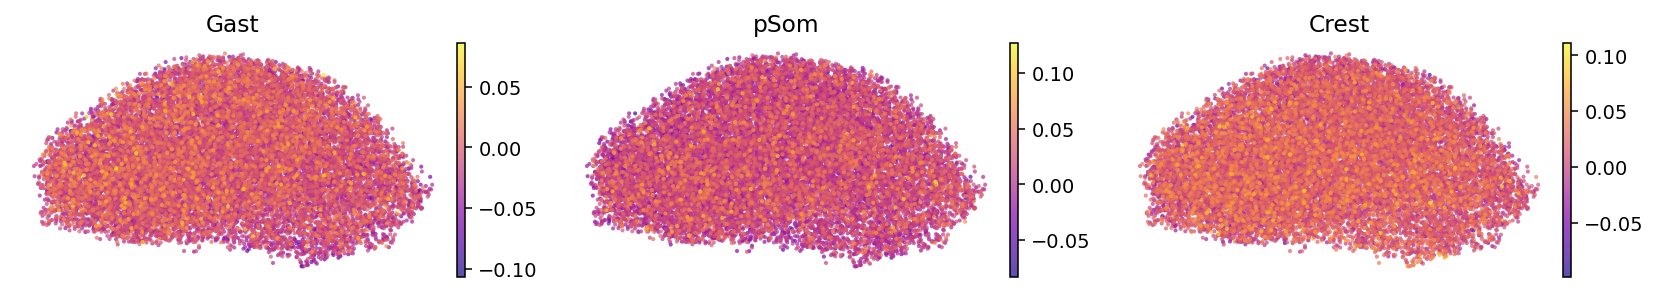

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(12, 2.2))
for i, m in enumerate(['Gast','pSom','Crest']):
    sc.pl.umap(adata, color=m, cmap='plasma', size=18, alpha=.7, frameon=False, show=False,
               ax=ax[i], title=m, colorbar_loc='right')
plt.tight_layout(); plt.show()

### Per-module signature figures + colorbars (deliverable)
House style: `figsize=(3.5,1.5)`, pseudotime left->right (`X_umap_lin`), `size=30`, plasma, **raw** score
per cell so 10x dropout is visible; external colorbars written to `colorbars/`.

saved Gast_signature.pdf + colorbar
saved pSom_signature.pdf + colorbar
saved Crest_signature.pdf + colorbar


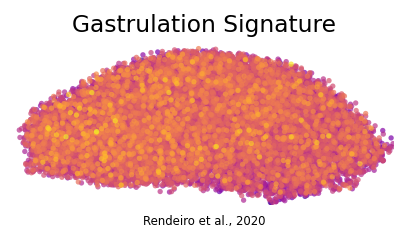

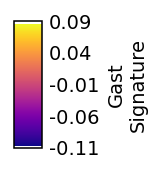

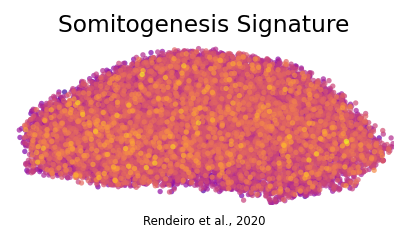

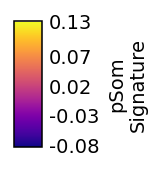

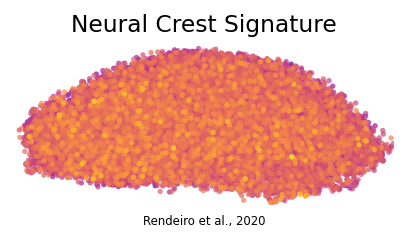

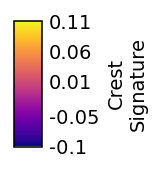

In [5]:
plot = adata.copy()
xl = plot.obsm['X_umap']
xlo, xhi = np.percentile(xl[:,0], [0.3, 99.7]); ylo, yhi = np.percentile(xl[:,1], [0.3, 99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
titles = {'Gast':'Gastrulation Signature','pSom':'Somitogenesis Signature','Crest':'Neural Crest Signature'}
for m in ['Gast','pSom','Crest']:
    fig, ax = plt.subplots(figsize=(3.5, 1.5))
    sc.pl.umap(plot, color=m, cmap='plasma', alpha=.7, size=30, colorbar_loc=None,
               frameon=False, show=False, ax=ax, title=titles[m])
    ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
    ax.text(.5, -.12, 'Rendeiro et al., 2020', ha='center', transform=ax.transAxes, size=6)
    fig.savefig(os.path.join(pth_fig, f'{m}_signature.pdf'), bbox_inches='tight')
    lo, hi_ = float(adata.obs[m].min()), float(adata.obs[m].max())
    ticks = np.round(np.linspace(lo, hi_, 5), 2)
    fcb = plt.figure(figsize=(.66, 1)); cax = fcb.add_axes([.35, .05, .3, .9])
    cb = plt.colorbar(ax.collections[0], cax=cax); cb.ax.tick_params(which='both', size=0)
    cb.set_label(f'{m}\nSignature'); cb.set_ticks(ticks, labels=ticks); cb.solids.set_alpha(1)
    fcb.savefig(os.path.join(pth_cb, f'{m}_colorbar.pdf'), bbox_inches='tight')
    plt.show(); print('saved', f'{m}_signature.pdf', '+ colorbar')

### Save signatures data

In [6]:
adata.write(os.path.join(pth_in, 'signatures.h5ad'))
print('saved signatures.h5ad', adata.shape)

saved signatures.h5ad (18314, 14889)
